<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4b_complexos_sistemas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio IV (b): sistemas de equações com números complexos

## Fasores, o Newton que já sabe o jacobiano, e as raízes que fogem do eixo real

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 4](X4_complexos.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4_complexos.ipynb)) · **Anterior:** [X4a_complexos_algebra.ipynb](X4a_complexos_algebra.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4a_complexos_algebra.ipynb)) · **Próximo:** [X4c_complexos_edo.ipynb](X4c_complexos_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X4c_complexos_edo.ipynb))

**Objetivo.** Três usos de complexos em sistemas de equações, cada um com uma lição numérica:
- **fasores:** um sistema de molas forçado por uma força senoidal, no regime permanente, vira um **sistema linear complexo**. O módulo da solução é a amplitude, o argumento é a fase. É o método que os engenheiros eletricistas usam em circuitos de corrente alternada;
- **Newton complexo:** para uma função analítica, o jacobiano do Newton em duas variáveis tem uma estrutura especial (as equações de Cauchy–Riemann), e o Newton se escreve como no notebook I(b), $z\leftarrow z-f(z)/f'(z)$, com complexos. As bacias de atração formam um **fractal**;
- **raízes de polinômios:** todo polinômio de grau $n$ tem $n$ raízes complexas (o teorema fundamental da álgebra), e o computador as calcula como **autovalores** de uma matriz. O polinômio de Wilkinson mostra que essas raízes podem ser extremamente mal condicionadas.

**Roteiro**
1. Fasores: molas forçadas no regime permanente
2. Newton complexo, Cauchy–Riemann e o fractal de Newton
3. Raízes de polinômios: a matriz companheira e o polinômio de Wilkinson
4. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy.integrate import solve_ivp
rng = np.random.default_rng(42)

---

## 1. Fasores: molas forçadas no regime permanente

**Um bloco.** Um bloco de massa $m$ com mola $k$ e atrito viscoso $c$, empurrado por uma força $F_0\cos\omega t$:
$$m\ddot x+c\dot x+kx=F_0\cos\omega t .$$
O truque dos fasores: escrever a força como a parte real de $F_0e^{i\omega t}$ e procurar uma solução da forma $x(t)=\operatorname{Re}\big(Xe^{i\omega t}\big)$, com $X$ um número **complexo** constante. Derivar vira multiplicar por $i\omega$, e a equação diferencial vira uma equação **algébrica**:
$$(k-m\omega^2+ic\omega)\,X=F_0\quad\Longrightarrow\quad X=\frac{F_0}{k-m\omega^2+ic\omega}.$$
O módulo $\lvert X\rvert$ é a amplitude da oscilação, e $\arg X$ é o atraso de fase em relação à força. Depois que o transitório morre (o atrito o apaga), é isso que se vê.

**Três blocos.** Os três blocos entre paredes do notebook I(b), agora com atrito em cada um e uma força senoidal no primeiro, dão um sistema linear complexo $3\times3$:
$$\big(\mathbf K-\omega^2\mathbf M+i\omega\mathbf C\big)\mathbf X=\mathbf F .$$
A célula resolve o sistema complexo, confere com o sistema **real** equivalente de $6\times6$ (partes reais e imaginárias separadas), e confere com uma simulação no tempo: depois de o transitório morrer, a amplitude simulada deve ser $\lvert X_j\rvert$.

In [2]:
def rigidez(ks):
    n = len(ks) - 1
    K = np.zeros((n, n))
    for i in range(n):
        K[i, i] = ks[i] + ks[i + 1]
        if i + 1 < n:
            K[i, i + 1] = K[i + 1, i] = -ks[i + 1]
    return K

Km = rigidez([100.0, 50.0, 80.0, 120.0])                 # as molas do notebook I(b)
Mm = np.diag([1.0, 2.0, 1.5]); Cm = np.diag([0.5, 0.5, 0.5])
F0 = np.array([1.0, 0.0, 0.0])                          # força de 1 N no bloco 1

def fasor(w):
    return np.linalg.solve(Km - w**2 * Mm + 1j * w * Cm, F0.astype(complex))

w_teste = 6.0
X = fasor(w_teste)
print(f"ω = {w_teste} rad/s:  amplitudes |X| = {np.abs(X).round(5)} m;  fases arg X = {np.degrees(np.angle(X)).round(1)}°")

# o sistema real equivalente: (A + iB)(x + iy) = f  ⇔  [[A, −B], [B, A]] [x; y] = [f; 0]
A_, B_ = Km - w_teste**2 * Mm, w_teste * Cm
real6 = np.linalg.solve(np.block([[A_, -B_], [B_, A_]]), np.r_[F0, np.zeros(3)])
confere("sistema complexo 3×3 = sistema real 6×6", X, real6[:3] + 1j * real6[3:], tol=1e-15)

# a simulação no tempo
def f_tempo(t, s):
    x, v = s[:3], s[3:]
    return np.r_[v, np.linalg.solve(Mm, F0 * np.cos(w_teste * t) - Km @ x - Cm @ v)]
T_sim = 120.0
sol = solve_ivp(f_tempo, (0, T_sim), np.zeros(6), rtol=1e-10, atol=1e-12, dense_output=True, max_step=0.01)
tt = np.linspace(T_sim - 2 * np.pi / w_teste * 5, T_sim, 4000)       # as últimas cinco oscilações
amp_sim = 0.5 * (sol.sol(tt)[:3].max(1) - sol.sol(tt)[:3].min(1))
print(f"amplitude simulada depois de {T_sim:.0f} s: {amp_sim.round(5)}")
confere("amplitude simulada = |X| (o transitório já morreu)", amp_sim, np.abs(X), tol=1e-4, relativo=True)

ω = 6.0 rad/s:  amplitudes |X| = [0.01444 0.04907 0.02688] m;  fases arg X = [-136.1 -151.4 -152.6]°
OK   sistema complexo 3×3 = sistema real 6×6:  diferença máxima = 2.50e-17


amplitude simulada depois de 120 s: [0.01444 0.04907 0.02688]
OK   amplitude simulada = |X| (o transitório já morreu):  diferença relativa máxima = 1.05e-07


**A curva de ressonância.** Varrendo $\omega$, a amplitude de cada bloco tem picos nas frequências naturais do sistema, que são as raízes de $\det(\mathbf K-\omega^2\mathbf M)=0$: os autovalores do problema $\mathbf K\mathbf v=\omega^2\mathbf M\mathbf v$. A célula desenha a curva e marca as frequências naturais.

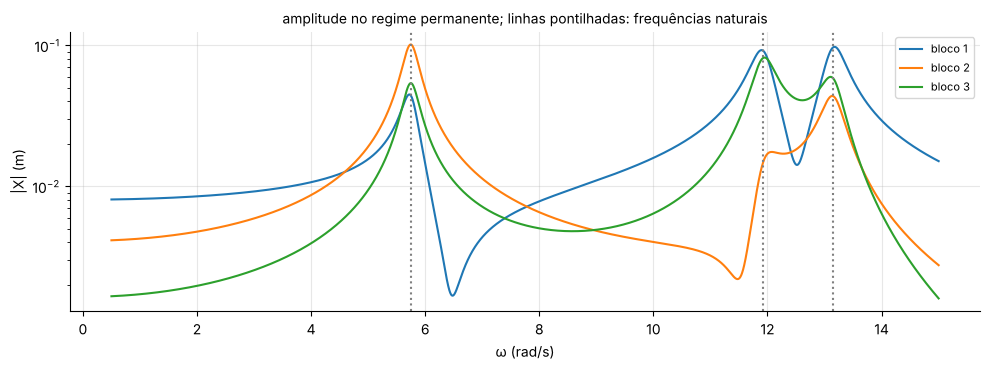

frequências naturais: [ 5.7482 11.9275 13.154 ] ;  picos do bloco 1: [ 5.722 11.896 13.177]
OK   os picos estão nas frequências naturais (atrito fraco):  diferença relativa máxima = 2.40e-03


In [3]:
from scipy.linalg import eigh
ws = np.linspace(0.5, 15, 3000)
amps = np.array([np.abs(fasor(w)) for w in ws])
w_nat = np.sqrt(eigh(Km, Mm, eigvals_only=True))
fig, ax = plt.subplots(figsize=(10, 3.8))
for j in range(3):
    ax.semilogy(ws, amps[:, j], label=f"bloco {j + 1}")
for wn in w_nat:
    ax.axvline(wn, color="gray", ls=":")
ax.set_xlabel("ω (rad/s)"); ax.set_ylabel("|X| (m)"); ax.legend(fontsize=8)
ax.set_title("amplitude no regime permanente; linhas pontilhadas: frequências naturais", fontsize=10)
plt.tight_layout(); plt.show()
picos = [ws[np.argmax(amps[:, 0] * ((ws > a) & (ws < b)))] for a, b in [(0, (w_nat[0] + w_nat[1]) / 2), ((w_nat[0] + w_nat[1]) / 2, (w_nat[1] + w_nat[2]) / 2), ((w_nat[1] + w_nat[2]) / 2, 20)]]
print("frequências naturais:", w_nat.round(4), ";  picos do bloco 1:", np.round(picos, 3))
confere("os picos estão nas frequências naturais (atrito fraco)", picos, w_nat, tol=0.01, relativo=True)

**Leitura.** Um sistema de equações diferenciais virou, para cada frequência, um sistema linear complexo pequeno. A simulação no tempo precisou de dois minutos simulados para o transitório morrer (com um minuto, o resto do transitório ainda aparecia na quarta casa); o fasor dá a resposta direto. Os três picos estão nas frequências naturais, com o atrito fraco deslocando-os muito pouco. A fase (não desenhada) passa por $-90°$ em cada ressonância.

---

## 2. Newton complexo, Cauchy–Riemann e o fractal de Newton

Uma função complexa $f(z)$, com $z=x+iy$ e $f=u+iv$, é também uma função de ℝ² em ℝ²: $(x,y)\mapsto(u,v)$. Para resolver $f(z)=0$, o Newton em duas variáveis do notebook I(b) usa o jacobiano $2\times2$. Quando $f$ é **analítica** (derivável no sentido complexo: polinômios, exponenciais, senos...), esse jacobiano tem uma forma especial, dada pelas **equações de Cauchy–Riemann**, $u_x=v_y$ e $u_y=-v_x$:

$$\mathbf J=\begin{bmatrix}u_x&u_y\\v_x&v_y\end{bmatrix}=\begin{bmatrix}a&-b\\b&a\end{bmatrix},\qquad f'(z)=a+ib .$$

É a matriz de um **número complexo** (notebook IV(a), seção 1). Resolver $\mathbf J\,\Delta=-\mathbf f$ é dividir por $f'(z)$, e o Newton em duas variáveis se escreve numa linha: $z\leftarrow z-f(z)/f'(z)$.

In [4]:
x, y = sp.symbols("x y", real=True)
zs = x + sp.I * y
f_s = zs**3 - 1
u, v = sp.re(sp.expand(f_s)), sp.im(sp.expand(f_s))
J_s = sp.Matrix([[u.diff(x), u.diff(y)], [v.diff(x), v.diff(y)]])
print("f(z) = z³ − 1:   u =", u, ";  v =", v)
print("Cauchy–Riemann: u_x − v_y =", sp.simplify(u.diff(x) - v.diff(y)), ";  u_y + v_x =", sp.simplify(u.diff(y) + v.diff(x)))
fl = sp.expand(3 * zs**2)
print("o jacobiano é a matriz do complexo f'(z) = 3z²:", sp.simplify(J_s - sp.Matrix([[sp.re(fl), -sp.im(fl)], [sp.im(fl), sp.re(fl)]])).tolist())

def newton_real2(p, n=6):
    Jn, un, vn = sp.lambdify((x, y), J_s), sp.lambdify((x, y), u), sp.lambdify((x, y), v)
    for _ in range(n):
        p = p - np.linalg.solve(np.array(Jn(*p), float), [un(*p), vn(*p)])
    return p

def newton_complexo(z, n=6):
    for _ in range(n):
        z = z - (z**3 - 1) / (3 * z**2)
    return z

confere("Newton complexo = Newton em duas variáveis (6 passos de 0,4 + 0,9i)",
        newton_complexo(0.4 + 0.9j), complex(*newton_real2(np.array([0.4, 0.9]))), tol=1e-14)

f(z) = z³ − 1:   u = x**3 - 3*x*y**2 - 1 ;  v = 3*x**2*y - y**3
Cauchy–Riemann: u_x − v_y = 0 ;  u_y + v_x = 0
o jacobiano é a matriz do complexo f'(z) = 3z²: [[0, 0], [0, 0]]
OK   Newton complexo = Newton em duas variáveis (6 passos de 0,4 + 0,9i):  diferença máxima = 3.61e-15


**O fractal de Newton.** O polinômio $z^3-1$ tem três raízes: $1$, $e^{2\pi i/3}$ e $e^{-2\pi i/3}$. Para cada chute inicial $z_0$ numa grade do plano, o Newton converge para uma delas (ou não converge). Pintando cada chute com a cor da raiz que ele encontra, aparecem as **bacias de atração**, como as do tiro direto e do tiro por cima no notebook II(b). Aqui, a fronteira entre as bacias é um **fractal**: em qualquer ponto da fronteira, por mais que se aproxime, as três cores aparecem. Um chute perto da fronteira pode convergir para qualquer das três raízes.

O Newton complexo vetorizado faz isso numa grade de $800\times800$ pontos em uma fração de segundo.

raiz (1+0j)                 : 34.19% dos chutes
raiz (-0.5+0.866j)          : 32.90% dos chutes
raiz (-0.5-0.866j)          : 32.90% dos chutes
não convergiu               :  0.00% dos chutes
OK   as bacias das duas raízes complexas são espelhos uma da outra:  diferença máxima = 0.00e+00


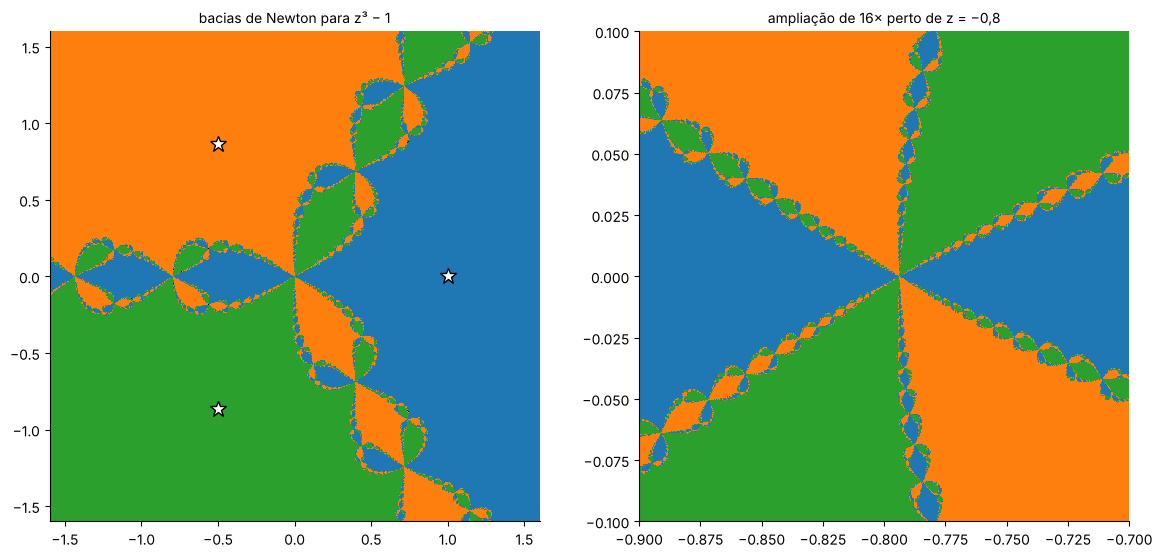

In [5]:
n_px = 800
xs = np.linspace(-1.6, 1.6, n_px)
Zg = xs[None, :] + 1j * xs[:, None]
raizes = np.exp(2j * np.pi * np.arange(3) / 3)
Z = Zg.copy()
with np.errstate(all="ignore"):
    for it in range(40):
        Z = Z - (Z**3 - 1) / (3 * Z**2)
dist = np.abs(Z[..., None] - raizes)
cor = np.where(np.min(dist, -1) < 1e-8, np.argmin(dist, -1), 3)
for k in range(4):
    nome = f"raiz {np.round(raizes[k], 3)}" if k < 3 else "não convergiu"
    print(f"{nome:28s}: {100 * np.mean(cor == k):5.2f}% dos chutes")
confere("as bacias das duas raízes complexas são espelhos uma da outra", cor[::-1, :] == 1, cor == 2, tol=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))
cmap = plt.matplotlib.colors.ListedColormap(["tab:blue", "tab:orange", "tab:green", "black"])
ax[0].imshow(cor, origin="lower", extent=[-1.6, 1.6, -1.6, 1.6], cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest")
ax[0].plot(raizes.real, raizes.imag, "w*", ms=12, mec="k"); ax[0].set_title("bacias de Newton para z³ − 1", fontsize=10)
# zoom numa fronteira
xs2 = np.linspace(-0.9, -0.7, n_px); Z2 = xs2[None, :] + 1j * np.linspace(-0.1, 0.1, n_px)[:, None]
with np.errstate(all="ignore"):
    for it in range(60):
        Z2 = Z2 - (Z2**3 - 1) / (3 * Z2**2)
cor2 = np.where(np.min(np.abs(Z2[..., None] - raizes), -1) < 1e-8, np.argmin(np.abs(Z2[..., None] - raizes), -1), 3)
ax[1].imshow(cor2, origin="lower", extent=[-0.9, -0.7, -0.1, 0.1], cmap=cmap, vmin=-0.5, vmax=3.5, interpolation="nearest")
ax[1].set_title("ampliação de 16× perto de z = −0,8", fontsize=10)
for a_ in ax:
    a_.grid(False)
plt.tight_layout(); plt.show()

**Leitura.** As bacias das duas raízes complexas são espelhos uma da outra (o polinômio tem coeficientes reais, e o Newton comuta com o conjugado), e as três ocupam perto de um terço da janela cada (a janela quadrada quebra um pouco a simetria de 120° do problema). Nenhum chute da grade deixou de convergir: os pontos de onde o Newton cai exatamente em $z=0$, onde $f'(0)=0$, existem, mas formam um conjunto sem área. A ampliação mostra a mesma estrutura em escala menor: a fronteira tem infinitos "bulbos" das três cores. É a versão extrema do aviso do notebook II(b): **o resultado de um Newton depende do chute**, e perto de uma fronteira a dependência é caótica.

---

## 3. Raízes de polinômios: a matriz companheira e o polinômio de Wilkinson

**O teorema fundamental da álgebra.** Todo polinômio de grau $n\geq1$ com coeficientes complexos tem exatamente $n$ raízes complexas (contando multiplicidades). Em ℝ isso falha ($x^2+1$ não tem raiz real); em ℂ, nunca. É a razão de fundo pela qual os autovalores de qualquer matriz quadrada existem, ainda que complexos.

**Como o computador acha raízes.** Não por fórmulas (para grau 5 ou mais, não existem fórmulas com radicais), nem por Newton de raiz em raiz. O `np.roots` monta a **matriz companheira**, cujo polinômio característico é o polinômio dado, e calcula os seus **autovalores** com o algoritmo QR. Para $p(x)=x^n+a_{n-1}x^{n-1}+\dots+a_0$:

$$\mathbf C=\begin{bmatrix}-a_{n-1}&-a_{n-2}&\cdots&-a_1&-a_0\\1&0&\cdots&0&0\\0&1&\cdots&0&0\\\vdots&&\ddots&&\vdots\\0&0&\cdots&1&0\end{bmatrix}.$$

In [6]:
lam = sp.Symbol("lambda")
a0, a1, a2 = sp.symbols("a0 a1 a2")
C3 = sp.Matrix([[-a2, -a1, -a0], [1, 0, 0], [0, 1, 0]])
print("det(λI − C) =", sp.expand((lam * sp.eye(3) - C3).det()), "  ← o polinômio de volta")

coef = [1, -6, 11, -6]                                  # (x − 1)(x − 2)(x − 3)
Cn = np.diag(np.ones(2), -1); Cn[0, :] = -np.array(coef[1:])
confere("autovalores da companheira = np.roots", np.sort(np.linalg.eigvals(Cn).real), np.sort(np.roots(coef).real), tol=1e-12)
print("raízes de x² + 1:", np.roots([1, 0, 1]), "  ← sem raiz real, mas com duas complexas")

det(λI − C) = a0 + a1*lambda + a2*lambda**2 + lambda**3   ← o polinômio de volta
OK   autovalores da companheira = np.roots:  diferença máxima = 0.00e+00
raízes de x² + 1: [-0.+1.j  0.-1.j]   ← sem raiz real, mas com duas complexas


**O polinômio de Wilkinson.** Em 1959, James Wilkinson estudou o polinômio
$$w(x)=(x-1)(x-2)\cdots(x-20),$$
com as raízes $1,2,\dots,20$, bem separadas. Ele mudou **um** coeficiente, o de $x^{19}$ (que vale $-210$), por $2^{-23}\approx1{,}2\times10^{-7}$, uma mudança relativa de $6\times10^{-10}$. Várias raízes viraram **pares complexos**, longe do eixo real.

A explicação é a sensibilidade. Se o coeficiente $a_{19}$ muda de $\delta$, a raiz $r$ muda de aproximadamente
$$\delta r\approx-\frac{r^{19}}{w'(r)}\,\delta .$$
Para as raízes do meio, $r^{19}$ é enorme e $w'(r)$, nem tanto: a sensibilidade $\lvert\partial r/\partial a_{19}\rvert$ chega a $2\times10^9$. O cálculo abaixo usa aritmética exata (`sympy`) para os coeficientes, para que o efeito venha da perturbação, e não de arredondamentos na montagem do polinômio.

coeficiente de x¹⁹: -210 ;  maior coeficiente em módulo: 1.380e+19



raízes depois de mudar a₁₉ em 2⁻²³ (≈ 1,2·10⁻⁷):
     1.00000 +  0.00000 i
     2.00000 +  0.00000 i
     3.00000 +  0.00000 i
     4.00000 +  0.00000 i
     5.00000 +  0.00000 i
     6.00001 +  0.00000 i
     6.99970 +  0.00000 i
     8.00727 +  0.00000 i
     8.91725 +  0.00000 i
    10.09527 −  0.64350 i
    10.09527 +  0.64350 i
    11.79363 −  1.65233 i
    11.79363 +  1.65233 i
    13.99236 −  2.51883 i
    13.99236 +  2.51883 i
    16.73074 −  2.81262 i
    16.73074 +  2.81262 i
    19.50244 −  1.94033 i
    19.50244 +  1.94033 i
    20.84691 +  0.00000 i

|∂r/∂a₁₉| = |r¹⁹ / w'(r)| para r = 1..20:
    8e-18 8e-11 2e-06 2e-03 6e-01 6e+01 3e+03 6e+04 8e+05 8e+06 5e+07 2e+08 6e+08 1e+09 2e+09 2e+09 2e+09 1e+09 3e+08 4e+07
a raiz mais sensível é r = 16: uma mudança de 1e-7 no coeficiente a move em ~287 (a aproximação linear já não vale)
OK   o polinômio perturbado tem raízes complexas:  diferença máxima = 0.00e+00
OK   as raízes pequenas quase não se movem:  diferença máxima = 7.24

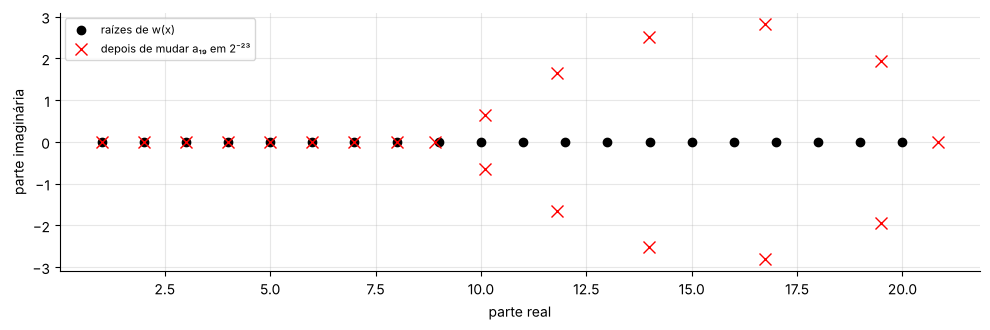

In [7]:
xs_ = sp.Symbol("x")
w_poly = sp.Poly(sp.prod([xs_ - k for k in range(1, 21)]), xs_)
coefs = [int(ci) for ci in w_poly.all_coeffs()]
print("coeficiente de x¹⁹:", coefs[1], ";  maior coeficiente em módulo:", f"{max(abs(ci) for ci in coefs):.3e}")
pert = sp.Poly(w_poly.as_expr() - sp.Rational(1, 2**23) * xs_**19, xs_)
raizes_pert = np.array([complex(r) for r in sp.Poly(pert, xs_).nroots(n=30, maxsteps=200)])
raizes_pert = raizes_pert[np.argsort(raizes_pert.real)]
print("\nraízes depois de mudar a₁₉ em 2⁻²³ (≈ 1,2·10⁻⁷):")
for r in raizes_pert:
    print(f"   {r.real:9.5f} {'+' if r.imag >= 0 else '−'} {abs(r.imag):8.5f} i")

wl = sp.diff(w_poly.as_expr(), xs_)
cond = [float(abs(sp.Integer(k)**19 / wl.subs(xs_, k))) for k in range(1, 21)]
print("\n|∂r/∂a₁₉| = |r¹⁹ / w'(r)| para r = 1..20:")
print("   ", " ".join(f"{ci:.0e}" for ci in cond))
k_max = int(np.argmax(cond)) + 1
print(f"a raiz mais sensível é r = {k_max}: uma mudança de 1e-7 no coeficiente a move em ~{cond[k_max - 1] * 2**-23:.0f} (a aproximação linear já não vale)")
confere("o polinômio perturbado tem raízes complexas", np.max(np.abs(raizes_pert.imag)) > 1, True)
confere("as raízes pequenas quase não se movem", np.abs(raizes_pert[:5] - np.arange(1, 6)), np.zeros(5), tol=1e-6)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(np.arange(1, 21), np.zeros(20), "ko", label="raízes de w(x)")
ax.plot(raizes_pert.real, raizes_pert.imag, "rx", ms=8, label="depois de mudar a₁₉ em 2⁻²³")
ax.set_xlabel("parte real"); ax.set_ylabel("parte imaginária"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.** As raízes de 1 a 5 quase não se movem (sensibilidade pequena), mas a partir de 10 elas se juntam em pares e saltam para fora do eixo real, com partes imaginárias de até quase 3. Uma mudança de menos de uma parte em um bilhão num coeficiente mudou a **natureza** das raízes. A lição de Wilkinson, que ele chamou de "o polinômio pérfido": **raízes de polinômios são, em geral, um problema mal condicionado quando escritas pelos coeficientes**. É por isso que, na prática, não se calculam autovalores de uma matriz passando pelo polinômio característico (o caminho é o inverso: polinômio → matriz companheira → QR), e por isso que os filtros de Kalman e os controladores são projetados com matrizes, e não com polinômios de grau alto.

> **Nota: o que isto tem a ver com estabilidade.** Um sistema linear $\dot{\mathbf x}=\mathbf A\mathbf x$ é estável quando todos os autovalores de $\mathbf A$ têm parte real negativa. Se esses autovalores fossem calculados pelas raízes de um polinômio característico de grau alto, um arredondamento poderia mover um autovalor para o lado instável. É o mesmo fenômeno da figura, e uma das razões pelas quais a teoria de controle moderna trocou polinômios por espaços de estados.

---

## 4. Exercícios

1. **Fase na ressonância.** Desenhe a fase $\arg X_1(\omega)$ do bloco 1 na seção 1. Confira que ela passa por $-90°$ perto de cada frequência natural (com atrito fraco). O que acontece com a fase do bloco 3?
2. **Circuito RLC.** Um resistor $R$, um indutor $L$ e um capacitor $C$ em série, com tensão $V_0\cos\omega t$. Escreva a impedância $Z=R+i\omega L+1/(i\omega C)$ e a corrente $I=V_0/Z$. Qual é a analogia com o bloco com mola (quem é a massa, quem é a mola)?
3. **Newton para $z^4-1$ e para $z^3-2z+2$.** Desenhe as bacias. No segundo caso, aparecem regiões grandes de não convergência: encontre um ciclo de período 2 do Newton (dica: parta de $z=0$).
4. **Durand–Kerner.** O método de Weierstrass (ou Durand–Kerner) calcula **todas** as raízes ao mesmo tempo: $z_k\leftarrow z_k-p(z_k)/\prod_{j\neq k}(z_k-z_j)$. Implemente-o para $x^5-1$ e compare com `np.roots`.
5. **Wilkinson e o `np.roots`.** Calcule as raízes de $w(x)$ **sem** perturbação, com `np.roots` e os coeficientes em `float`. Elas são 1, 2, ..., 20? Qual é o maior erro, e por quê, se ninguém perturbou nada?